# ENVIRONNEMENT

In [1]:
import numpy as np


class GridWorld:
    """
    10x10 environment.

    Agent: red pixel
    Goal: not needed for JEPA training
    Wall: black pixels
    Door: opening in the wall

    Actions:
        0 = up
        1 = down
        2 = left
        3 = right
    """

    def __init__(self, size=10):
        self.size = size

        self.action_to_delta = {
            0: (-1, 0),  # up
            1: (1, 0),   # down
            2: (0, -1), # left
            3: (0, 1),  # right
        }

        self.reset()

    def reset(self):
        # Randomly initialize the wall and door
        self.wall_x = np.random.randint(1, self.size - 1)
        self.wall_x = 5

        # Door consists of two adjacent cells
        door_y_start = np.random.randint(0, self.size - 1)
        self.door_y = [door_y_start, door_y_start + 1]
        self.door_y = [7,8]

        # Randomly sample a valid agent state
        return self.sample_state()

    def sample_state(self):
        """
        Randomly sample a valid agent position for the
        current wall/door configuration.

        Returns:
            RGB image representing the sampled state.
        """
        valid_positions = []

        for y in range(self.size):
            for x in range(self.size):
                if self.valid_position(y, x):
                    valid_positions.append((y, x))

        # Randomly select one valid position
        self.agent_pos = np.array(
            valid_positions[np.random.randint(len(valid_positions))],
            dtype=np.int64
        )

        return self.render()

    def valid_position(self, y, x):
        # Outside grid
        if y < 0 or y >= self.size or x < 0 or x >= self.size:
            return False

        # Wall occupies wall_x, except at the door
        if x == self.wall_x and y not in self.door_y:
            return False

        return True

    def step(self, action):
        dy, dx = self.action_to_delta[action]

        y, x = self.agent_pos

        new_y = y + dy
        new_x = x + dx

        # Only move if the destination is valid
        if self.valid_position(new_y, new_x):
            self.agent_pos[:] = [new_y, new_x]

        return self.render()

    def render(self):
        """
        Returns an RGB image of shape (size, size, 3).

        Background = white
        Wall = black
        Agent = red
        """

        image = np.ones(
            (self.size, self.size, 3),
            dtype=np.float32
        )

        # Wall
        for y in range(self.size):
            if y not in self.door_y:
                image[y, self.wall_x] = [0.0, 0.0, 0.0]

        # Agent
        y, x = self.agent_pos
        image[y, x] = [1.0, 0.0, 0.0]

        return image


if __name__ == "__main__":
    env = GridWorld()

    # Every reset randomly generates a new wall/door configuration
    x = env.reset()

    print("Wall x:", env.wall_x)
    print("Door y:", env.door_y)
    print("Agent position:", env.agent_pos)
    print("Image shape:", x.shape)

    for action in [3, 3, 3, 0, 0]:
        x = env.step(action)

    print(x.shape)

    # Can also sample another random agent state
    # without changing the wall/door configuration.
    x = env.sample_state()

    print("New agent position:", env.agent_pos)

Wall x: 5
Door y: [7, 8]
Agent position: [1 9]
Image shape: (10, 10, 3)
(10, 10, 3)
New agent position: [7 4]


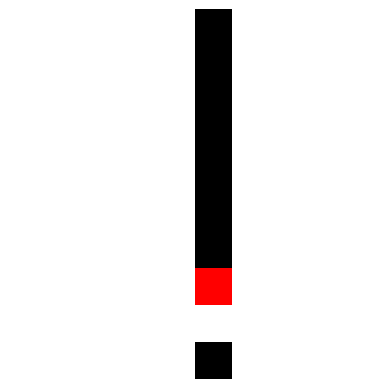

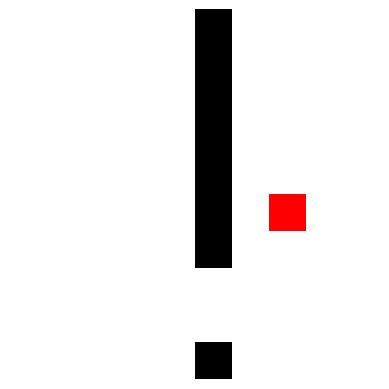

In [2]:
import matplotlib.pyplot as plt

env = GridWorld()
x = env.reset()

plt.imshow(x)
plt.axis("off")
plt.show()

x = env.sample_state()

plt.imshow(x)
plt.axis("off")
plt.show()

# MODELS

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import copy


class Encoder(nn.Module):
    """
    Image -> latent representation
    """

    def __init__(self, latent_dim=64):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Flatten(),

            nn.Linear(64 * 10 * 10, latent_dim)
        )

    def forward(self, x):
        return self.network(x)

class Decoder(nn.Module):
    """
    latent representation -> Action
    """

    def __init__(self, latent_dim=64):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(latent_dim*2, 4),
        )

    def forward(self, x, x_next):
        # Concatenate state and action
        x = torch.cat([x, x_next], dim=-1)

        return self.network(x)


class Predictor(nn.Module):
    """
    (latent state, action) -> predicted next latent state
    """

    def __init__(self, latent_dim=64, num_actions=4):
        super().__init__()

        self.action_embedding = nn.Embedding(
            num_actions,
            latent_dim
        )

        self.network = nn.Sequential(
            nn.Linear(latent_dim * 2, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, latent_dim)
        )

    def forward(self, z, action):
        # action: [batch]
        a = self.action_embedding(action)

        # Concatenate state and action
        x = torch.cat([z, a], dim=-1)

        return self.network(x)

class LinearPredictor(nn.Module):
    """
    (latent state x, action u) -> predicted next latent state

    Implements:
        x' = x + A(x) u

    where A(x) is a matrix produced by a neural network.
    """

    def __init__(self, latent_dim=64, num_actions=4):
        super().__init__()

        # Network produces A(x), flattened.
        # For one-hot actions, A(x) has shape:
        # [latent_dim, num_actions]
        self.network = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, latent_dim * num_actions),
        )

    def forward(self, x, action):
        # x:      [batch, latent_dim]
        # action: [batch]  -- integer action index

        batch_size = x.shape[0]

        # A(x): [batch, latent_dim, num_actions]
        A = self.network(x).view(
            batch_size,
            -1,
            self.network[-1].out_features // x.shape[-1]
        )

        # One-hot action vector u: [batch, num_actions]
        u = F.one_hot(
            action,
            num_classes=A.shape[-1]
        ).float()

        # A(x)u: [batch, latent_dim]
        delta = torch.bmm(A, u.unsqueeze(-1)).squeeze(-1)

        # x' = x + A(x)u
        return x + delta


class JEPA(nn.Module):

    def __init__(self, latent_dim=64, linear = False):
        super().__init__()

        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)
        self.target_encoder = copy.deepcopy(self.encoder)
        self.linear = linear
        if linear:
            self.predictor = LinearPredictor(latent_dim)
        else:
            self.predictor = Predictor(latent_dim)

    def encode(self, x):
        return self.encoder(x)

    def predict(self, z, action):
        return self.predictor(z, action)

    def forward(self, x_t, action):
        z_t = self.encode(x_t)
        z_next_pred = self.predict(z_t, action)

        return z_next_pred

# TRAINING

In [4]:
def generate_dataset(num_transitions=50000):

    env = GridWorld()

    states = []
    actions = []
    next_states = []
    goal_states = []

    for _ in range(num_transitions):

        # -------------------------
        # Sample a new environment
        # -------------------------
        env.reset()

        # -------------------------
        # Sample valid current state
        # -------------------------
        state = env.sample_state()

        # -------------------------
        # Take action from S_t
        # -------------------------
        action = np.random.randint(0, 4)

        next_state = env.step(action)

        # -------------------------
        # Sample valid goal
        # -------------------------
        goal_state = env.sample_state()
        

        # -------------------------
        # Store transition
        # -------------------------
        states.append(state)
        actions.append(action)
        next_states.append(next_state)
        goal_states.append(goal_state)

    return (
        np.array(states),
        np.array(actions),
        np.array(next_states),
        np.array(goal_states)
    )

In [5]:
import numpy as np


def generate_trajectory_dataset(
    num_trajectories=5000,
    trajectory_length=20
):
    """
    Generate a dataset of trajectories.

    Returns
    -------
    states:
        Shape (N, T, H, W, C)

    actions:
        Shape (N, T-1)

    next_states:
        Shape (N, T-1, H, W, C)

    goal_states:
        Shape (N, H, W, C)

    where:
        N = number of trajectories
        T = trajectory length
    """

    env = GridWorld()

    all_states = []
    all_actions = []
    all_next_states = []
    all_goal_states = []

    for _ in range(num_trajectories):

        # -----------------------------------------------------
        # 1. Sample valid initial state
        # -----------------------------------------------------

        while True:
            agent_pos = np.array([
                np.random.randint(0, env.size),
                np.random.randint(0, env.size)
            ], dtype=np.int64)

            if env.valid_position(
                agent_pos[0],
                agent_pos[1]
            ):
                break

        env.agent_pos = agent_pos.copy()

        # -----------------------------------------------------
        # 2. Sample one valid goal for the trajectory
        # -----------------------------------------------------

        while True:
            goal_pos = np.array([
                np.random.randint(0, env.size),
                np.random.randint(0, env.size)
            ], dtype=np.int64)

            if (
                env.valid_position(
                    goal_pos[0],
                    goal_pos[1]
                )
                and not np.array_equal(
                    goal_pos,
                    agent_pos
                )
            ):
                break

        # -----------------------------------------------------
        # 3. Render the goal state
        # -----------------------------------------------------

        original_pos = env.agent_pos.copy()

        env.agent_pos = goal_pos.copy()
        goal_state = env.render()

        # Restore agent position
        env.agent_pos = original_pos

        # -----------------------------------------------------
        # 4. Generate trajectory
        # -----------------------------------------------------

        trajectory_states = []
        trajectory_actions = []
        trajectory_next_states = []

        for t in range(trajectory_length - 1):

            # Current state
            state = env.render()

            # Random action
            action = np.random.randint(0, 4)

            # Take action
            next_state = env.step(action)

            # Store transition
            trajectory_states.append(state)
            trajectory_actions.append(action)
            trajectory_next_states.append(next_state)

        # Add final state
        final_state = env.render()
        trajectory_states.append(final_state)

        # -----------------------------------------------------
        # 5. Convert trajectory to arrays
        # -----------------------------------------------------

        all_states.append(
            np.stack(trajectory_states)
        )

        all_actions.append(
            np.array(trajectory_actions, dtype=np.int64)
        )

        all_next_states.append(
            np.stack(trajectory_next_states)
        )

        all_goal_states.append(
            goal_state
        )

    # ---------------------------------------------------------
    # 6. Stack all trajectories
    # ---------------------------------------------------------

    states = np.stack(all_states)
    actions = np.stack(all_actions)
    next_states = np.stack(all_next_states)
    goal_states = np.stack(all_goal_states)

    return (
        states,
        actions,
        next_states,
        goal_states
    )

In [6]:
import torch
from torch.utils.data import Dataset, DataLoader


class TransitionDataset(Dataset):

    def __init__(
        self,
        states,
        actions,
        next_states,
        goal_states
    ):

        self.states = torch.tensor(
            states,
            dtype=torch.float32
        )

        self.actions = torch.tensor(
            actions,
            dtype=torch.long
        )

        self.next_states = torch.tensor(
            next_states,
            dtype=torch.float32
        )

        self.goal_states = torch.tensor(
            goal_states,
            dtype=torch.float32
        )

        # -----------------------------------------------------
        # Detect dataset type
        # -----------------------------------------------------

        if self.states.ndim == 4:
            # -----------------------------------------------
            # Transition dataset
            #
            # states: (N, H, W, C)
            # -----------------------------------------------

            self.is_trajectory = False

            self.states = self.states.permute(
                0, 3, 1, 2
            )

            self.next_states = self.next_states.permute(
                0, 3, 1, 2
            )

            self.goal_states = self.goal_states.permute(
                0, 3, 1, 2
            )

        elif self.states.ndim == 5:
            # -----------------------------------------------
            # Trajectory dataset
            #
            # states: (N, T, H, W, C)
            # -----------------------------------------------

            self.is_trajectory = True

            N, T, H, W, C = self.states.shape

            # (N, T, H, W, C)
            # -> (N, T, C, H, W)
            self.states = self.states.permute(
                0, 1, 4, 2, 3
            )

            # next_states:
            # (N, T-1, H, W, C)
            # -> (N, T-1, C, H, W)
            self.next_states = self.next_states.permute(
                0, 1, 4, 2, 3
            )

            # goal_states:
            # (N, H, W, C)
            # -> (N, C, H, W)
            self.goal_states = self.goal_states.permute(
                0, 3, 1, 2
            )

            self.num_trajectories = N
            self.trajectory_length = T

        else:
            raise ValueError(
                "states must have shape "
                "(N,H,W,C) or (N,T,H,W,C)"
            )

    def __len__(self):

        if self.is_trajectory:
            # Each timestep except the final state
            # corresponds to one transition.
            return (
                self.num_trajectories
                * (self.trajectory_length - 1)
            )

        else:
            return len(self.actions)

    def __getitem__(self, idx):

        if not self.is_trajectory:

            # ---------------------------------------------
            # Transition dataset
            # ---------------------------------------------

            return (
                self.states[idx],
                self.actions[idx],
                self.next_states[idx],
                self.goal_states[idx]
            )

        else:

            # ---------------------------------------------
            # Trajectory dataset
            # ---------------------------------------------

            # Convert flat index into:
            #
            # trajectory index i
            # timestep t
            #
            T_minus_1 = self.trajectory_length - 1

            trajectory_idx = idx // T_minus_1
            timestep = idx % T_minus_1

            state = self.states[
                trajectory_idx,
                timestep
            ]

            action = self.actions[
                trajectory_idx,
                timestep
            ]

            next_state = self.next_states[
                trajectory_idx,
                timestep
            ]

            # Same goal for the whole trajectory
            goal_state = self.goal_states[
                trajectory_idx
            ]

            return (
                state,
                action,
                next_state,
                goal_state
            )

In [7]:
import torch


def sigreg_loss(z, num_projections=64, num_knots=17, t_max=3.0):
    """
    Sketched Isotropic Gaussian Regularization (SIGReg).

    z: (B, D)
    """

    B, D = z.shape

    # Random normalized projections
    projections = torch.randn(
        D,
        num_projections,
        device=z.device,
        dtype=z.dtype
    )

    projections = projections / (
        projections.norm(dim=0, keepdim=True) + 1e-8
    )

    # Project latent representations
    # (B, D) -> (B, num_projections)
    z_proj = z @ projections

    # Evaluation points
    t = torch.linspace(
        0.0,
        t_max,
        num_knots,
        device=z.device,
        dtype=z.dtype
    )

    # Gaussian characteristic function
    target_cf = torch.exp(-0.5 * 1 * t.square())
    # Empirical characteristic function
    angles = z_proj.unsqueeze(-1) * t

    empirical_cf = torch.exp(
        1j * angles
    ).mean(dim=0)

    # Squared difference from N(0,1)
    error = (
        empirical_cf
        - target_cf.unsqueeze(0)
    ).abs().square()

    # Trapezoidal integration
    dt = t[1] - t[0]

    weights = torch.ones_like(t)
    weights[0] *= 0.5
    weights[-1] *= 0.5

    loss = (
        error
        * weights.unsqueeze(0)
    ).sum(dim=-1) * dt

    return loss.mean()

In [8]:
import torch
import torch.nn.functional as F


def train_jepa(
    model,
    train_loader,
    num_epochs=30,
    lr=1e-3,
    tau=0.99,
    device="cuda"
):
    model = model.to(device)

    # Only optimize the online/context encoder and predictor.
    # The target encoder is updated exclusively through EMA.
    optimizer_encoder = torch.optim.AdamW(
        list(model.encoder.parameters()),
        lr=lr,
        weight_decay=1e-4
    )
    optimizer_predictor = torch.optim.AdamW(
        list(model.predictor.parameters()) + 
        list(model.decoder.parameters()),
        lr=lr,
        weight_decay=1e-4
    )

    for epoch in range(num_epochs):

        model.train()
        total_loss = 0.0

        for x_t, action, x_next, x_goal in train_loader:

            x_t = x_t.to(device).reshape(-1, *x_t.shape[-3:])
            x_goal = x_goal.to(device)
            action = action.to(device)
            x_next = x_next.to(device).reshape(-1, *x_next.shape[-3:])

            # ------------------------------------------------
            # 1. Encode current observation with online encoder
            # ------------------------------------------------
            z_t = model.encoder(x_t)
            z_goal = model.encoder(x_goal)
            z_next = model.encoder(x_next)

            # ------------------------------------------------
            # 2. Predict next latent state
            # ------------------------------------------------
            z_next_pred = model.predictor(
                z_t,
                action
            )

            # ------------------------------------------------
            # 3. Encode next observation with target encoder
            # ------------------------------------------------
            with torch.no_grad():
                z_t_target = model.target_encoder(x_t)
                z_next_target = model.target_encoder(x_next)
                z_goal_target = model.target_encoder(x_goal)

            # ------------------------------------------------
            # 4. JEPA loss
            # ------------------------------------------------
            same_state = torch.all(
                x_t == x_goal,
                dim=tuple(range(1, x_t.ndim))
            )
            cost = (~same_state).float()
            Vloss = - cost - 0.99*torch.norm(z_next_target-z_goal_target, dim = -1) + torch.norm(z_t-z_goal, dim = -1)
            Vloss = torch.where(
                Vloss < 0,
                0.3 * Vloss**2,
                0.7 * Vloss**2
            ).mean()
           

            F = z_t /torch.sqrt(torch.sum(z_t**2, dim=0, keepdim=True) + 1e-8)
            G = F.T@F/F.shape[0]
            sign,logdet = torch.linalg.slogdet(
                G + 1e-8*torch.eye(G.shape[0], device=G.device)
            )
            
            action_rec = model.decoder(z_t,z_next)

            pred_error = torch.norm(z_next_pred-z_next, dim=-1)
            C = torch.relu(torch.norm(z_next_pred - z_t, dim=-1) - cost)
            reg = torch.abs(100-torch.norm(z_t-z_goal, dim=-1, p=1))
            action_rec_loss = nn.CrossEntropyLoss()(action_rec,action.long())
            sigreg = sigreg_loss(z_t)
            invert_loss = -logdet

            
            #jepa_loss = 10*torch.relu(torch.norm(z_next - z_t, dim=-1) - cost)**2 + torch.abs(10000-torch.norm(z_t-z_goal, dim=-1, p=1))

            jepa_loss = pred_error**2 + action_rec_loss
            #jepa_loss = Vloss

            loss = (
                jepa_loss
            ).mean(dim=-1)
            

            # ------------------------------------------------
            # 5. Update online encoder + predictor
            # ------------------------------------------------
            optimizer_encoder.zero_grad()
            optimizer_predictor.zero_grad()
            loss.backward()
            optimizer_predictor.step()
            optimizer_encoder.step()

            # ------------------------------------------------
            # 6. EMA update of target encoder
            # ------------------------------------------------
            with torch.no_grad():

                for target_param, online_param in zip(
                    model.target_encoder.parameters(),
                    model.encoder.parameters()
                ):
                    target_param.data.mul_(1.0-tau)
                    target_param.data.add_(
                        (tau) * online_param.data
                    )

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        print(
            f"Epoch {epoch + 1:03d} | "
            f"Loss: {avg_loss:.6f}"
        )
        with torch.no_grad():
            print(
                "mean:", z_t.mean().item(),
                "std:", z_t.std(dim=0).mean().item(),
                "norm:", z_t.norm(dim=-1).mean().item(),
                "pred error:", pred_error.mean().item(),
                "C:", torch.norm(z_next_pred - z_t, dim=-1).mean().item(),
                "actions:", action_rec.mean().item(),
                "sigreg:", sigreg.mean().item(),
            )
    return model

In [9]:
import torch
import torch.nn.functional as F


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Generate data
states, actions, next_states, goals = generate_dataset(
    50000
)

dataset = TransitionDataset(
    states,
    actions,
    next_states,
    goals
)

train_loader = DataLoader(
    dataset,
    batch_size=256,
    shuffle=True
)

In [11]:
# Model
model = JEPA(
    latent_dim=128, linear = True
)

device = "cuda" if torch.cuda.is_available() else "cpu"

In [12]:
model = train_jepa(
    model,
    train_loader,
    num_epochs=25,
    lr=1e-3,
    tau=1.0,
    device=device
)

Epoch 001 | Loss: 1.400539
mean: -0.0056616878136992455 std: 0.013142487034201622 norm: 0.3814328610897064 pred error: 0.07074381411075592 C: 0.05305908992886543 actions: -0.017591087147593498 sigreg: 1.3859150409698486
Epoch 002 | Loss: 0.748423
mean: -0.056716907769441605 std: 0.8274993896484375 norm: 9.94931411743164 pred error: 0.25526824593544006 C: 2.1388328075408936 actions: -0.051879506558179855 sigreg: 0.3361507058143616
Epoch 003 | Loss: 0.150810
mean: -0.035156480967998505 std: 0.8992495536804199 norm: 10.395395278930664 pred error: 0.18226665258407593 C: 2.7530393600463867 actions: 0.03485388681292534 sigreg: 0.30805742740631104
Epoch 004 | Loss: 0.107638
mean: -0.03868374228477478 std: 0.9332247972488403 norm: 10.85425090789795 pred error: 0.18405869603157043 C: 2.727766752243042 actions: -0.01871620863676071 sigreg: 0.31066685914993286
Epoch 005 | Loss: 0.093290
mean: 0.01235460676252842 std: 0.9478777050971985 norm: 10.805617332458496 pred error: 0.14822497963905334 C: 2

# VISUALIZATION

In [13]:
import numpy as np
import torch
import matplotlib.pyplot as plt


@torch.no_grad()
def latent_distance_map(
    model,
    target_pos,
    device="cuda",
):
    """
    Compute the latent-space distance between a target state
    and every possible agent position.

    target_pos: (y, x)
    """

    model.eval()
    device = torch.device(device)

    env = GridWorld()

    # ---------------------------------------------------------
    # 1. Encode the target state
    # ---------------------------------------------------------

    env.agent_pos = np.array(target_pos, dtype=np.int64)

    target_image = env.render()


    target_image = torch.tensor(
        target_image,
        dtype=torch.float32
    )

    # H,W,C -> 1,C,H,W
    target_image = target_image.permute(
        2, 0, 1
    ).unsqueeze(0).to(device)

    # Encode target
    target_z = model.encoder(
        target_image
    )

    z = model.predictor(target_z, torch.tensor([2]).to(device))
    print(torch.norm(model.predictor(target_z, torch.tensor([0]).to(device))- target_z, dim=-1))
    target_z = z


    # ---------------------------------------------------------
    # 2. Compute distance for every position
    # ---------------------------------------------------------

    distance_map = np.full(
        (env.size, env.size),
        np.nan
    )

    for y in range(env.size):

        for x in range(env.size):

            # Skip wall positions
            if not env.valid_position(y, x):
                continue

            # Put agent at this position
            env.agent_pos = np.array(
                [y, x],
                dtype=np.int64
            )

            image = env.render()

            image = torch.tensor(
                image,
                dtype=torch.float32
            )

            image = image.permute(
                2, 0, 1
            ).unsqueeze(0).to(device)

            # Encode
            z = model.encoder(image)

            d = torch.norm(
                (z - target_z),
                dim=-1, p=2
            )
            
            distance_map[y, x] = d.item()

    return distance_map

In [14]:
# ---------------------------------------------------------
# Choose target state
# ---------------------------------------------------------

target_pos = (0,3)

tensor([0.0897], device='cuda:0')


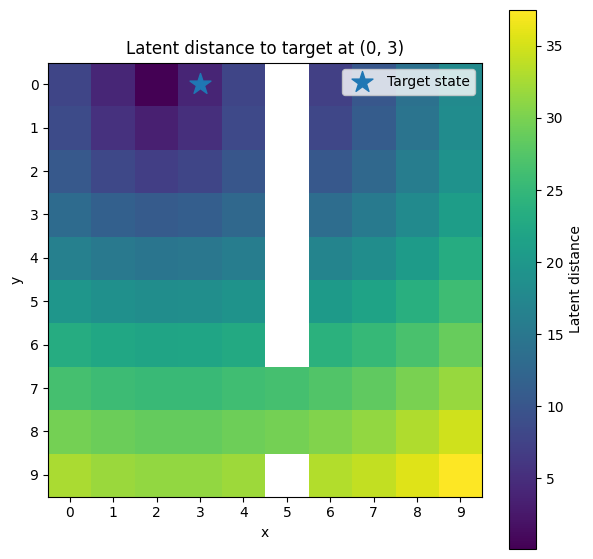

In [15]:
# ---------------------------------------------------------
# Compute latent distances
# ---------------------------------------------------------

distance_map = latent_distance_map(
    model,
    target_pos=target_pos,
    device=device,)


# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.imshow(
    distance_map,
    origin="upper"
)

plt.colorbar(
    label="Latent distance"
)

# Mark target
plt.scatter(
    target_pos[1],
    target_pos[0],
    marker="*",
    s=250,
    label="Target state"
)

plt.xticks(range(10))
plt.yticks(range(10))

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    f"Latent distance to target at {target_pos}"
)

plt.legend()

plt.show()

In [16]:
import numpy as np
import plotly.graph_objects as go

# Enumerate valid agent positions for the current environment configuration.
valid_positions = [
    (y, x_pos)
    for y in range(env.size)
    for x_pos in range(env.size)
    if env.valid_position(y, x_pos)
]

# Render and encode each position.
original_pos = env.agent_pos.copy()
images = []

for y, x_pos in valid_positions:
    env.agent_pos = np.array([y, x_pos], dtype=np.int64)
    images.append(env.render())

env.agent_pos = original_pos

images = torch.tensor(
    np.stack(images),
    dtype=torch.float32,
    device=device
).permute(0, 3, 1, 2)

model.eval()
with torch.no_grad():
    embeddings = model.encoder(images).cpu().numpy()

# Use the existing embeddings from the notebook.
centered = embeddings - embeddings.mean(axis=0, keepdims=True)
u, singular_values, _ = np.linalg.svd(centered, full_matrices=False)

# Keep the first 3 principal components
pca_3d = u[:, :3] * singular_values[:3]
explained = singular_values[:3] ** 2 / np.sum(singular_values ** 2)

# Optional: keep a stable ordering for hover/labels
positions = np.array(valid_positions, dtype=int)

fig = go.Figure(
    data=[
        go.Scatter3d(
            x=pca_3d[:, 0],
            y=pca_3d[:, 1],
            z=pca_3d[:, 2],
            mode="markers+text",
            text=[f"({y},{x})" for y, x in valid_positions],
            textposition="top center",
            customdata=positions,
            marker=dict(
                size=5,
                color=np.arange(len(valid_positions)),
                colorscale="Viridis",
                opacity=0.9,
                showscale=True,
                colorbar=dict(title="Grid index")
            ),
            hovertemplate=(
                "Position: (%{customdata[0]}, %{customdata[1]})<br>"
                "PC1: %{x:.3f}<br>"
                "PC2: %{y:.3f}<br>"
                "PC3: %{z:.3f}<extra></extra>"
            ),
        )
    ]
)

fig.update_layout(
    title="3D PCA of state embeddings",
    width=900,
    height=700,
    scene=dict(
        xaxis_title=f"PC1 ({explained[0]:.1%} variance)",
        yaxis_title=f"PC2 ({explained[1]:.1%} variance)",
        zaxis_title=f"PC3 ({explained[2]:.1%} variance)",
        camera=dict(
            eye=dict(x=1.8, y=1.8, z=1.6)
        ),
        dragmode="orbit",
    ),
    margin=dict(l=0, r=0, b=0, t=50),
)

fig.show()